# 04 · Hyperparameter tuning

**Goal:** tune LightGBM and CatBoost on the final 41-feature set (`features_engineered.json`), and confirm any gain honestly.

**Protocol**
1. **Search** with Optuna (TPE sampler, seeded): **100 LightGBM** and **60 CatBoost** trials. Each trial is scored on **one 5-fold split** (seed 0) to keep it fast: ~7 s per LightGBM trial, 30–60 s per CatBoost trial. The search uses a slightly higher learning rate (LightGBM 0.03, CatBoost 0.05) for speed.
2. **Confirm** the best parameters on all **15 folds** (5-fold × 3 seeds), at the search learning rate and at a lower one, and compare **fold by fold** with the untuned models from `03_features`.
   - The search picked parameters on seed-0 folds, so the comparison is also reported on **seeds 1–2 only** (10 folds the search never scored). That's the less biased estimate.
3. **Monotone constraints** (LightGBM): force conversion to rise with credit score and fall with quoted price. The EDA shows both relationships are monotone; constraints can make the model steadier and easier to explain.
4. Save the chosen parameters and tree counts to `models/params_tuned.json`.

Studies are stored in `models/optuna.db` (git-ignored), so an interrupted run resumes where it stopped.

In [1]:
import json, sys
import numpy as np, pandas as pd, optuna, matplotlib.pyplot as plt
sys.path.insert(0, '.')
import common as C, features as FE
optuna.logging.set_verbosity(optuna.logging.WARNING)

lab, hold = C.load()
lab = FE.add_static(lab)
FEATS = json.load(open('features_engineered.json'))['lgb']['features']
untuned = {m: C.cv_score(f'fe_final_{m}', lab, FEATS, model=m) for m in ('lgb', 'cb')}  # cached from 03_features
STORE = 'sqlite:///optuna.db'
fmt = {'auc_mean': '{:.4f}', 'auc_se': '{:.4f}', 'Δ auc': '{:+.4f}', 'se Δ': '{:.4f}', 'top_decile_prec': '{:.1%}'}
print({m: round(r['auc_mean'], 4) for m, r in untuned.items()}, f'| {len(FEATS)} features')

{'lgb': np.float64(0.7049), 'cb': np.float64(0.7078)} | 41 features


## 1. LightGBM search
| Parameter | Range | Controls |
|---|---|---|
| `num_leaves` | 4–64 (log) | tree complexity |
| `max_depth` | −1 (none), 3–10 | caps interaction depth |
| `min_child_samples` | 10–400 (log) | minimum quotes per leaf (noise control) |
| `feature_fraction` | 0.2–1.0 | share of features per tree (decorrelates trees) |
| `bagging_fraction` | 0.5–1.0 | share of rows per tree |
| `lambda_l1`, `lambda_l2` | 1e-3–10 / 1e-3–30 (log) | leaf-weight regularization |
| `min_split_gain` | 0–0.5 | minimum improvement to split |
| `cat_smooth` | 1–100 (log) | smoothing for categorical splits |

In [2]:
def lgb_space(t):
    return dict(learning_rate=0.03, num_leaves=t.suggest_int('num_leaves', 4, 64, log=True),
                max_depth=t.suggest_categorical('max_depth', [-1, 3, 4, 5, 6, 8, 10]),
                min_child_samples=t.suggest_int('min_child_samples', 10, 400, log=True),
                feature_fraction=t.suggest_float('feature_fraction', 0.2, 1.0), bagging_fraction=t.suggest_float('bagging_fraction', 0.5, 1.0),
                lambda_l1=t.suggest_float('lambda_l1', 1e-3, 10, log=True), lambda_l2=t.suggest_float('lambda_l2', 1e-3, 30, log=True),
                min_split_gain=t.suggest_float('min_split_gain', 0, 0.5), cat_smooth=t.suggest_float('cat_smooth', 1, 100, log=True))

def objective(model, space):
    def f(t):
        r = C.cv_score('trial', lab, FEATS, model=model, params=space(t), seeds=(0,), log=False, cache=False)
        t.set_user_attr('rounds', r['rounds']); t.set_user_attr('top_decile_prec', r['top_decile_prec'])
        return r['auc_mean']
    return f

def run_study(name, model, space, n):
    st = optuna.create_study(study_name=name, storage=STORE, direction='maximize', load_if_exists=True,
                             sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=15))
    st.optimize(objective(model, space), n_trials=max(0, n - len(st.trials)))
    return st

seed0 = {m: untuned[m]['fold_aucs'][:5].mean() for m in untuned}  # untuned score on the same seed-0 folds
lgb_study = run_study('lgb_v1', 'lgb', lgb_space, 100)
print(f"LightGBM best seed-0 AUC {lgb_study.best_value:.4f} (untuned on same folds {seed0['lgb']:.4f}), rounds {lgb_study.best_trial.user_attrs['rounds']}")
lgb_study.trials_dataframe().sort_values('value', ascending=False).head(8).filter(regex='^(value|params_|user_attrs_rounds)').round(4)

LightGBM best seed-0 AUC 0.7068 (untuned on same folds 0.7048), rounds 395


,value,params_bagging_fraction,params_cat_smooth,params_feature_fraction,params_lambda_l1,params_lambda_l2,params_max_depth,params_min_child_samples,params_min_split_gain,params_num_leaves,user_attrs_rounds
98,0.7068,0.9133,57.1246,0.9765,0.0025,0.0046,4,31,0.3098,6,395
96,0.7065,0.9078,76.2017,0.9749,0.0014,0.0067,4,40,0.3035,7,454
92,0.7064,0.9417,90.8029,0.9661,0.0013,0.0079,4,35,0.3002,7,374
76,0.7063,0.9235,68.6991,0.9559,0.0124,0.0020,4,28,0.3279,8,288
29,0.7063,0.9423,50.5282,0.9299,0.0029,0.0324,4,50,0.4122,6,499
53,0.7061,0.8721,87.7880,0.8743,0.0057,0.0024,4,29,0.3850,7,356
38,0.7061,0.9457,63.6837,0.9295,0.0014,0.0122,4,32,0.2655,6,368
17,0.7061,0.9037,22.0909,0.8723,0.3722,0.0054,3,19,0.2557,11,394


## 2. CatBoost search
| Parameter | Range | Controls |
|---|---|---|
| `depth` | 4–8 | symmetric tree depth (interaction order) |
| `l2_leaf_reg` | 1–30 (log) | leaf-value regularization |
| `random_strength` | 0.1–10 (log) | noise added to split scores (prevents over-fitting) |
| `bagging_temperature` | 0–3 | strength of Bayesian row bootstrap |
| `border_count` | 32 / 64 / 128 / 254 | bins per numeric feature |
| `one_hot_max_size` | 2 / 4 / 10 | categoricals with ≤ this many levels are one-hot; others use target statistics |

In [3]:
def cb_space(t):
    return dict(learning_rate=0.05, depth=t.suggest_int('depth', 4, 8), l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 30, log=True),
                random_strength=t.suggest_float('random_strength', 0.1, 10, log=True),
                bagging_temperature=t.suggest_float('bagging_temperature', 0, 3),
                border_count=t.suggest_categorical('border_count', [32, 64, 128, 254]),
                one_hot_max_size=t.suggest_categorical('one_hot_max_size', [2, 4, 10]))

cb_study = run_study('cb_v1', 'cb', cb_space, 60)
print(f"CatBoost best seed-0 AUC {cb_study.best_value:.4f} (untuned on same folds {seed0['cb']:.4f}), rounds {cb_study.best_trial.user_attrs['rounds']}")
cb_study.trials_dataframe().sort_values('value', ascending=False).head(8).filter(regex='^(value|params_|user_attrs_rounds)').round(4)

CatBoost best seed-0 AUC 0.7131 (untuned on same folds 0.7086), rounds 304


,value,params_bagging_temperature,params_border_count,params_depth,params_l2_leaf_reg,params_one_hot_max_size,params_random_strength,user_attrs_rounds
32,0.7131,2.2213,32,4,8.9037,10,0.5161,304.0
56,0.7127,2.6818,32,4,11.2286,10,0.7468,359.0
51,0.7127,2.8981,32,4,10.3671,10,0.2202,307.0
18,0.7125,1.8770,32,4,17.3070,10,0.1773,230.0
58,0.7124,2.9003,32,4,8.1758,10,0.3820,277.0
47,0.7123,2.1162,32,4,11.8002,10,0.7582,284.0
36,0.7121,2.4657,32,4,9.6223,10,0.5964,301.0
46,0.7120,2.2293,32,4,12.6707,10,0.6781,300.0


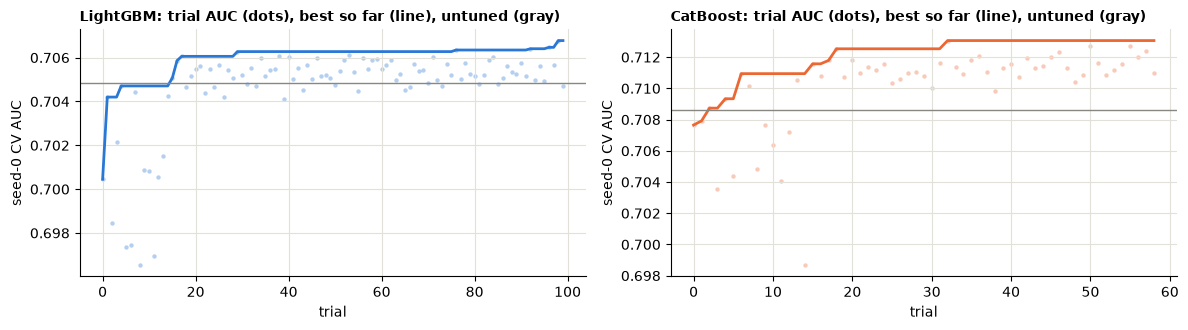

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, (name, st), color in zip(axes, [('LightGBM', lgb_study), ('CatBoost', cb_study)], ['#2a78d6', '#eb6834']):
    v = np.array([t.value for t in st.trials if t.value is not None])
    ax.scatter(range(len(v)), v, s=10, color=color, alpha=.35, lw=0)
    ax.plot(np.maximum.accumulate(v), color=color, lw=2)
    ax.axhline(seed0['lgb' if name == 'LightGBM' else 'cb'], color='#898781', lw=1)
    ax.set_title(f'{name}: trial AUC (dots), best so far (line), untuned (gray)', loc='left', fontsize=10, fontweight='bold')
    ax.set_xlabel('trial'); ax.set_ylabel('seed-0 CV AUC'); ax.spines[['top', 'right']].set_visible(False); ax.grid(color='#e1e0d9')
fig.tight_layout(); fig.savefig('figures/04_tuning_history.png', bbox_inches='tight')

**Search findings**
- **Both searches converge on shallow, regularized trees.**
  - LightGBM: `max_depth` 4, 6–8 leaves, a high `min_split_gain` (~0.3), nearly all features and rows per tree.
  - CatBoost: `depth` 4, only 32 bins per numeric feature, strong row bootstrapping (`bagging_temperature` ≈ 2–3), `l2_leaf_reg` ≈ 9–17.
  - The signal is mostly main effects plus low-order interactions; deeper trees mostly fit noise.
- **CatBoost** one-hot-encodes all remaining categoricals (`one_hot_max_size` 10 ≥ the 4–10 levels of state, carrier and package) rather than using target statistics.
- **Both searches plateau:**
  - LightGBM: ~0.706 by trial 30.
  - CatBoost: ~0.713 by trial 32.
  - More trials wouldn't help. Top trials of each model have nearly identical settings, so the optimum is stable rather than a lucky trial.

## 3. Confirm on all 15 folds
Candidates (all paired against the untuned model of the same family):
- **LightGBM:** tuned at the search learning rate (0.03) and at 0.015 (more, smaller steps); the better one with monotone constraints.
- **CatBoost:** tuned at the search learning rate (0.05) and at 0.03.

`Δ seeds 1–2` is the paired difference on the 10 folds the search never scored. It's the honest estimate of the tuning gain.

In [5]:
MONO = {'CREDIT_SCORE': 1, 'QUOTED_AMT': -1}
lgb_best, cb_best = lgb_space(optuna.trial.FixedTrial(lgb_study.best_params)), cb_space(optuna.trial.FixedTrial(cb_study.best_params))
cand = {'lgb': {'tuned lr .03': lgb_best, 'tuned lr .015': lgb_best | {'learning_rate': 0.015}},
        'cb': {'tuned lr .05': cb_best, 'tuned lr .03': cb_best | {'learning_rate': 0.03}}}
res = {m: {'untuned': untuned[m]} for m in cand}
for m, cs in cand.items():
    for n, p in cs.items():
        res[m][n] = C.cv_score(f'tune_{m}_{n}', lab, FEATS, model=m, params=p, notes=f'tuning confirm: {n}')
best_lgb = max(cand['lgb'], key=lambda n: res['lgb'][n]['auc_mean'])
cand['lgb']['tuned + monotone'] = cand['lgb'][best_lgb] | dict(monotone_constraints=[MONO.get(f, 0) for f in FEATS], monotone_constraints_method='advanced')
res['lgb']['tuned + monotone'] = C.cv_score('tune_lgb_monotone', lab, FEATS, params=cand['lgb']['tuned + monotone'], notes='tuning confirm: monotone')

def table(m):
    t = C.summary(list(res[m].values()), baseline=untuned[m]['name']).rename(index=dict(zip([r['name'] for r in res[m].values()], res[m])))
    d12 = {n: r['fold_aucs'][5:] - untuned[m]['fold_aucs'][5:] for n, r in res[m].items()}
    t['Δ seeds 1–2'] = {n: v.mean() for n, v in d12.items()}
    t['se (1–2)'] = {n: v.std() / np.sqrt(len(v)) for n, v in d12.items()}
    return t
conf = pd.concat({'LightGBM': table('lgb'), 'CatBoost': table('cb')})
conf.style.format(fmt | {'Δ seeds 1–2': '{:+.4f}', 'se (1–2)': '{:.4f}'})

**Confirmation findings**
- **CatBoost tuning is a real gain:** +0.0038 on the 10 folds the search never saw (≈ 5 se), +0.0039 on all 15.
  - The lower learning rate (0.03) is marginally better than the search rate.
  - Top-decile precision improves from 29.2% to **29.8%**.
- **LightGBM tuning is not a meaningful gain:** +0.0009 on 15 folds but only +0.0004 (≈ 0.7 se) on the unseen folds. LightGBM's defaults were already close to its optimum on this feature set.
- **Monotone constraints** (credit ↑, price ↓) **cost nothing** (+0.0008 vs +0.0009). They're a free option if the presentation needs a guarantee that the model never rewards a higher price.
- **CatBoost leads LightGBM by ~0.006 AUC.** A blend will mainly test whether LightGBM adds diversity.

## 4. Save the chosen configuration
Per model, the candidate with the best 15-fold AUC is chosen. If that's the untuned model, the defaults are kept. The saved record holds its full parameters, the CV-chosen number of trees (`rounds`) and its CV scores. `05_ensemble` and the final submission read this file.

In [6]:
chosen = {}
for m, label in (('lgb', 'LightGBM'), ('cb', 'CatBoost')):
    n = max(res[m], key=lambda k: res[m][k]['auc_mean'])
    params = C.RUNNERS[m][1] | ({} if n == 'untuned' else cand[m][n])
    chosen[m] = {'variant': n, 'params': params, 'rounds': res[m][n]['rounds'], 'cv_auc': res[m][n]['auc_mean'],
                 'cv_top_decile_prec': res[m][n]['top_decile_prec'], 'features': FEATS, 'cv_name': res[m][n]['name']}
    print(f"{label}: chose '{n}' | CV AUC {res[m][n]['auc_mean']:.4f} (untuned {untuned[m]['auc_mean']:.4f}) | {res[m][n]['rounds']} trees")
json.dump(chosen, open('params_tuned.json', 'w'), indent=1, default=str)
print('saved models/params_tuned.json')

LightGBM: chose 'tuned lr .03' | CV AUC 0.7058 (untuned 0.7049) | 408 trees
CatBoost: chose 'tuned lr .03' | CV AUC 0.7118 (untuned 0.7078) | 476 trees
saved models/params_tuned.json


**Progress**

| CV AUC (15 folds) | Baseline (77 features) | Selected (37) | + household features (41) | **+ tuning** |
|---|---|---|---|---|
| LightGBM | 0.6940 | 0.6956 | 0.7049 | **0.7058** |
| CatBoost | 0.6986 | 0.7011 | 0.7078 | **0.7118** |

**Total so far: CatBoost +0.013 AUC over its baseline.**

**Next (`05_ensemble`):**
- Seed averaging of the tuned models.
- XGBoost and a spline logistic regression for diversity.
- An out-of-fold-weighted rank blend.
- The final holdout submission.